In [1]:
# 2. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Generate reproducible synthetic daily retail data
dates = pd.date_range("2022-01-01", "2024-12-31", freq="D")
stores = [f"Store_{i}" for i in range(1, 6)]
products = [f"Product_{i}" for i in range(1, 9)]

store_effect = {s: np.random.uniform(0.8, 1.3) for s in stores}
product_effect = {p: np.random.uniform(8, 35) for p in products}
product_price = {p: np.random.uniform(5, 80) for p in products}

rows = []
for store in stores:
    for product in products:
        base = product_effect[product] * store_effect[store]
        price = product_price[product]
        for day in dates:
            day_num = day.dayofyear
            weekend_effect = 1.18 if day.dayofweek >= 5 else 1.0
            annual_effect = 1 + 0.18 * np.sin(2 * np.pi * day_num / 365.25)
            trend_effect = 1 + 0.00025 * (day - dates[0]).days
            holiday = int(day.month == 12 and day.day >= 20) or int(day.month == 1 and day.day <= 3)
            promotion = np.random.binomial(1, 0.12)
            promo_effect = 1.35 if promotion else 1.0
            holiday_effect = 1.25 if holiday else 1.0
            price_noise = np.random.normal(0, 0.015)
            daily_price = price * (1 - 0.08 * promotion) * (1 + price_noise)
            expected = base * weekend_effect * annual_effect * trend_effect * promo_effect * holiday_effect
            expected *= (price / daily_price) ** 0.35
            units = max(0, int(np.random.poisson(expected)))
            rows.append((day, store, product, daily_price, promotion, holiday, units))

df = pd.DataFrame(rows, columns=[
    "date", "store", "product", "price", "promotion", "holiday", "units_sold"
])
df = df.sort_values(["store", "product", "date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe(include="all"))

Dataset shape: (43840, 7)


,date,store,product,price,promotion,holiday,units_sold
0,2022-01-01,Store_1,Product_1,20.640421,0,1,17
1,2022-01-02,Store_1,Product_1,20.482137,0,1,18
2,2022-01-03,Store_1,Product_1,20.564158,0,1,13
3,2022-01-04,Store_1,Product_1,21.043358,0,0,11
4,2022-01-05,Store_1,Product_1,21.183615,0,0,10


,date,store,product,price,promotion,holiday,units_sold
count,43840,43840,43840,43840.000000,43840.000000,43840.000000,43840.000000
unique,NaN,5,8,NaN,NaN,NaN,NaN
top,NaN,Store_1,Product_1,NaN,NaN,NaN,NaN
freq,NaN,8768,5480,NaN,NaN,NaN,NaN
mean,2023-07-02 12:00:00,NaN,NaN,30.405386,0.120005,0.041058,30.322901
min,2022-01-01 00:00:00,NaN,NaN,16.273949,0.000000,0.000000,0.000000
25%,2022-10-01 18:00:00,NaN,NaN,19.222150,0.000000,0.000000,15.000000
50%,2023-07-02 12:00:00,NaN,NaN,27.207586,0.000000,0.000000,30.000000
75%,2024-04-01 06:00:00,NaN,NaN,39.102990,0.000000,0.000000,42.000000
max,2024-12-31 00:00:00,NaN,NaN,53.588155,1.000000,1.000000,122.000000


Missing values:


,missing_count
date,0
store,0
product,0
price,0
promotion,0
holiday,0
units_sold,0


Unique stores: 5
Unique products: 8
Date range: 2022-01-01 to 2024-12-31


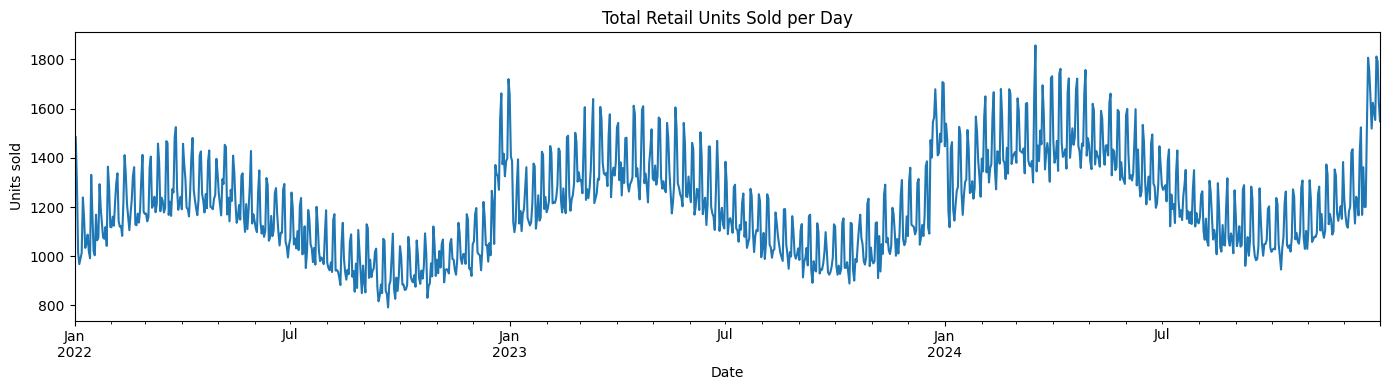

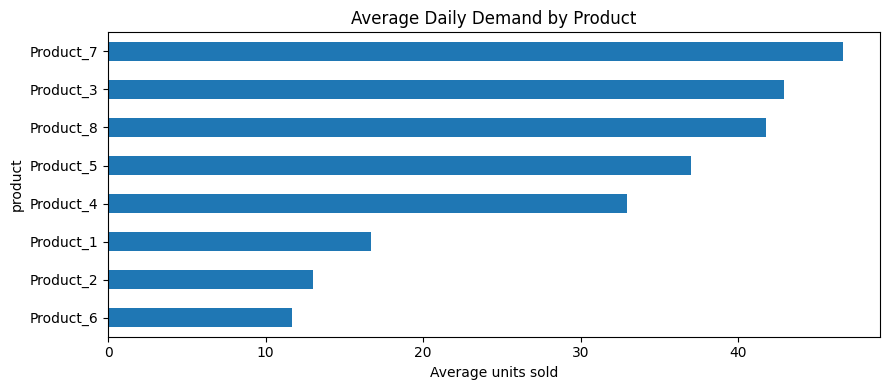

In [3]:
# Missing values and basic data checks
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

print("Unique stores:", df["store"].nunique())
print("Unique products:", df["product"].nunique())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

# Overall daily sales across all store-product combinations
daily_total = df.groupby("date")["units_sold"].sum()
plt.figure(figsize=(14, 4))
daily_total.plot()
plt.title("Total Retail Units Sold per Day")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()

# Average demand by product
product_demand = df.groupby("product")["units_sold"].mean().sort_values()
plt.figure(figsize=(9, 4))
product_demand.plot(kind="barh")
plt.title("Average Daily Demand by Product")
plt.xlabel("Average units sold")
plt.tight_layout()
plt.show()

In [4]:
def add_features(data):
    data = data.sort_values(["store", "product", "date"]).copy()
    data["day_of_week"] = data["date"].dt.dayofweek
    data["month"] = data["date"].dt.month
    data["day_of_year"] = data["date"].dt.dayofyear
    data["is_weekend"] = (data["day_of_week"] >= 5).astype(int)

    group = data.groupby(["store", "product"])["units_sold"]
    for lag in [1, 7, 28]:
        data[f"lag_{lag}"] = group.shift(lag)

    for window in [7, 28]:
        data[f"rolling_mean_{window}"] = (
            data.groupby(["store", "product"])["units_sold"]
                .transform(lambda s: s.shift(1).rolling(window).mean())
        )
        data[f"rolling_std_{window}"] = (
            data.groupby(["store", "product"])["units_sold"]
                .transform(lambda s: s.shift(1).rolling(window).std())
        )

    return data

featured = add_features(df)
featured = featured.dropna().reset_index(drop=True)

feature_cols = [
    "store", "product", "price", "promotion", "holiday",
    "day_of_week", "month", "day_of_year", "is_weekend",
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_std_7",
    "rolling_mean_28", "rolling_std_28"
]

X = pd.get_dummies(featured[feature_cols], columns=["store", "product"], dtype=int)
y = featured["units_sold"]

print("Model feature matrix:", X.shape)
display(X.head())

Model feature matrix: (42720, 27)


,price,promotion,holiday,day_of_week,month,day_of_year,is_weekend,lag_1,lag_7,lag_28,...,store_Store_4,store_Store_5,product_Product_1,product_Product_2,product_Product_3,product_Product_4,product_Product_5,product_Product_6,product_Product_7,product_Product_8
0,21.284144,0,0,5,1,29,1,14.0,20.0,17.0,...,0,0,1,0,0,0,0,0,0,0
1,21.161451,0,0,6,1,30,1,12.0,10.0,18.0,...,0,0,1,0,0,0,0,0,0,0
2,20.614522,0,0,0,1,31,0,17.0,16.0,13.0,...,0,0,1,0,0,0,0,0,0,0
3,20.747683,0,0,1,2,32,0,15.0,22.0,11.0,...,0,0,1,0,0,0,0,0,0,0
4,20.636843,0,0,2,2,33,0,10.0,11.0,10.0,...,0,0,1,0,0,0,0,0,0,0


In [5]:
cutoff = featured["date"].max() - pd.Timedelta(days=90)
train_mask = featured["date"] <= cutoff
test_mask = featured["date"] > cutoff

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Training period:", featured.loc[train_mask, "date"].min().date(),
      "to", featured.loc[train_mask, "date"].max().date())
print("Testing period:", featured.loc[test_mask, "date"].min().date(),
      "to", featured.loc[test_mask, "date"].max().date())
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Training period: 2022-01-29 to 2024-10-02
Testing period: 2024-10-03 to 2024-12-31
Train rows: 39120 | Test rows: 3600


In [6]:
# Baseline: previous 7-day average
baseline_pred = featured.loc[test_mask, "rolling_mean_7"].to_numpy()

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=250, max_depth=18, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=25,
        l2_regularization=1.0, random_state=RANDOM_STATE
    )
}

predictions = {"7-day Average Baseline": baseline_pred}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = np.maximum(0, model.predict(X_test))

print("Model training completed.")

Model training completed.


In [7]:
def wape(y_true, y_pred):
    denominator = np.sum(np.abs(y_true))
    return np.sum(np.abs(y_true - y_pred)) / denominator * 100 if denominator else np.nan

results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "WAPE (%)": wape(y_test.to_numpy(), pred)
    })

results_df = pd.DataFrame(results).sort_values("WAPE (%)").reset_index(drop=True)
display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
print("Best model on this test split:", best_model_name)

,Model,MAE,RMSE,WAPE (%)
0,Gradient Boosting,4.573,5.977,14.836
1,Random Forest,4.725,6.246,15.330
2,7-day Average Baseline,6.042,8.310,19.603


Best model on this test split: Gradient Boosting


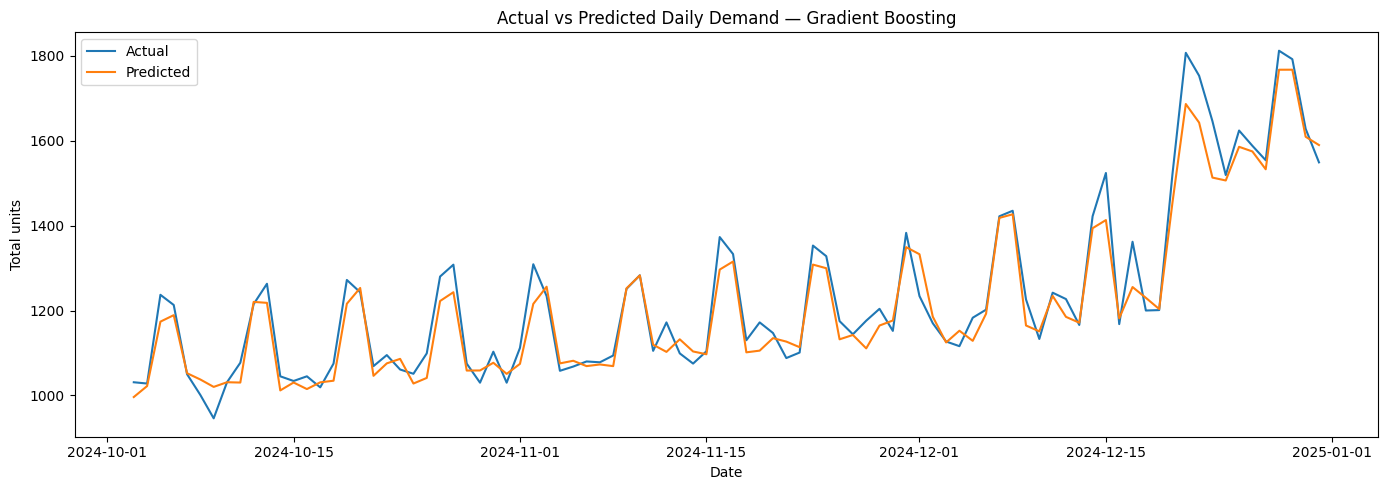

In [8]:
best_pred = predictions[best_model_name]
comparison = pd.DataFrame({
    "date": featured.loc[test_mask, "date"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": best_pred
}).groupby("date")[["actual", "predicted"]].sum()

plt.figure(figsize=(14, 5))
plt.plot(comparison.index, comparison["actual"], label="Actual")
plt.plot(comparison.index, comparison["predicted"], label="Predicted")
plt.title(f"Actual vs Predicted Daily Demand — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Total units")
plt.legend()
plt.tight_layout()
plt.show()

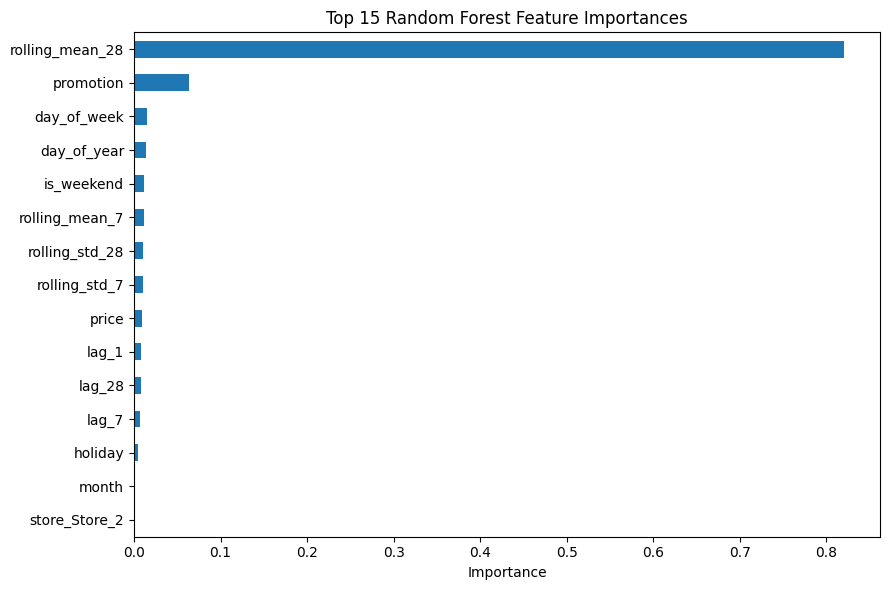

,importance
rolling_mean_28,0.820970
promotion,0.063035
day_of_week,0.014999
day_of_year,0.013809
is_weekend,0.012072
rolling_mean_7,0.011345
rolling_std_28,0.010453
rolling_std_7,0.010009
price,0.009717
lag_1,0.007826


In [9]:
rf_model = models["Random Forest"]
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.to_frame("importance"))

In [10]:
# Select a fitted ML estimator for recursive forecasting
if best_model_name in models:
    forecast_model = models[best_model_name]
else:
    forecast_model = models["Gradient Boosting"]

# Keep a full history for each store-product series
history = {
    (store, product): group.sort_values("date").copy()
    for (store, product), group in df.groupby(["store", "product"])
}

future_dates = pd.date_range(df["date"].max() + pd.Timedelta(days=1), periods=30, freq="D")
forecast_rows = []

# Align future one-row features to the training feature columns
for future_date in future_dates:
    day_predictions = []

    for (store, product), hist in history.items():
        hist = hist.sort_values("date")
        last = hist.iloc[-1]

        lag_1 = float(hist["units_sold"].iloc[-1])
        lag_7 = float(hist["units_sold"].iloc[-7])
        lag_28 = float(hist["units_sold"].iloc[-28])
        mean_7 = float(hist["units_sold"].tail(7).mean())
        std_7 = float(hist["units_sold"].tail(7).std())
        mean_28 = float(hist["units_sold"].tail(28).mean())
        std_28 = float(hist["units_sold"].tail(28).std())

        row = {
            "price": float(hist["price"].tail(28).mean()),
            "promotion": 0,
            "holiday": int(future_date.month == 12 and future_date.day >= 20)
                       or int(future_date.month == 1 and future_date.day <= 3),
            "day_of_week": future_date.dayofweek,
            "month": future_date.month,
            "day_of_year": future_date.dayofyear,
            "is_weekend": int(future_date.dayofweek >= 5),
            "lag_1": lag_1, "lag_7": lag_7, "lag_28": lag_28,
            "rolling_mean_7": mean_7, "rolling_std_7": std_7,
            "rolling_mean_28": mean_28, "rolling_std_28": std_28
        }

        # Add one-hot columns, then align exactly with training columns
        row_df = pd.DataFrame([row])
        row_df[f"store_{store}"] = 1
        row_df[f"product_{product}"] = 1
        row_df = row_df.reindex(columns=X_train.columns, fill_value=0)

        pred = max(0.0, float(forecast_model.predict(row_df)[0]))
        predicted_units = int(round(pred))

        forecast_rows.append({
            "date": future_date, "store": store, "product": product,
            "forecast_units": predicted_units
        })

        new_record = pd.DataFrame([{
            "date": future_date, "store": store, "product": product,
            "price": row["price"], "promotion": 0,
            "holiday": row["holiday"], "units_sold": predicted_units
        }])
        history[(store, product)] = pd.concat([hist, new_record], ignore_index=True)

forecast_df = pd.DataFrame(forecast_rows)
print("30-day forecast generated:", forecast_df.shape)
display(forecast_df.head(10))

30-day forecast generated: (1200, 4)


,date,store,product,forecast_units
0,2025-01-01,Store_1,Product_1,21
1,2025-01-01,Store_1,Product_2,16
2,2025-01-01,Store_1,Product_3,48
3,2025-01-01,Store_1,Product_4,39
4,2025-01-01,Store_1,Product_5,43
5,2025-01-01,Store_1,Product_6,14
6,2025-01-01,Store_1,Product_7,55
7,2025-01-01,Store_1,Product_8,43
8,2025-01-01,Store_2,Product_1,26
9,2025-01-01,Store_2,Product_2,21


In [12]:
LEAD_TIME_DAYS = 7
SERVICE_FACTOR = 1.65

historical_stats = (
    df.groupby(["store", "product"])["units_sold"]
    .agg(historical_mean="mean", historical_std="std")
    .reset_index()
)

future_summary = (
    forecast_df.groupby(["store", "product"])["forecast_units"]
    .agg(
        forecast_daily_mean="mean",
        forecast_daily_std="std",
        forecast_30_day_total="sum"
    )
    .reset_index()
)

inventory = future_summary.merge(
    historical_stats,
    on=["store", "product"]
)

inventory["daily_demand_for_planning"] = inventory["forecast_daily_mean"]

inventory["safety_stock"] = (
    SERVICE_FACTOR *
    inventory["historical_std"] *
    np.sqrt(LEAD_TIME_DAYS)
).round().astype(int)

inventory["reorder_point"] = (
    inventory["daily_demand_for_planning"] * LEAD_TIME_DAYS
    + inventory["safety_stock"]
).round().astype(int)

inventory = inventory.sort_values(
    "reorder_point", ascending=False
)

display(inventory.head(10))

,store,product,forecast_daily_mean,forecast_daily_std,forecast_30_day_total,historical_mean,historical_std,daily_demand_for_planning,safety_stock,reorder_point
14,Store_2,Product_7,58.766667,4.415360,1763,55.063869,13.523986,58.766667,59,470
10,Store_2,Product_3,54.733333,3.947355,1642,50.407847,12.494481,54.733333,55,438
30,Store_4,Product_7,53.200000,4.490603,1596,47.514599,11.656255,53.200000,51,423
22,Store_3,Product_7,52.600000,4.575798,1578,50.072080,12.263072,52.600000,54,422
23,Store_3,Product_8,51.700000,4.219413,1551,45.567518,11.711486,51.700000,51,413
18,Store_3,Product_3,49.400000,4.825221,1482,46.553832,11.690875,49.400000,51,397
15,Store_2,Product_8,48.633333,4.421603,1459,48.805657,11.916667,48.633333,52,392
12,Store_2,Product_5,48.433333,4.328600,1453,43.547445,10.403088,48.433333,45,384
26,Store_4,Product_3,47.833333,5.099583,1435,43.729015,11.123241,47.833333,49,384
31,Store_4,Product_8,46.066667,4.494697,1382,42.461679,10.528777,46.066667,46,368


Top 5 store-product combinations by forecast 30-day demand:


,store,product,forecast_30_day_total,safety_stock,reorder_point
14,Store_2,Product_7,1763,59,470
10,Store_2,Product_3,1642,55,438
30,Store_4,Product_7,1596,51,423
22,Store_3,Product_7,1578,54,422
23,Store_3,Product_8,1551,51,413


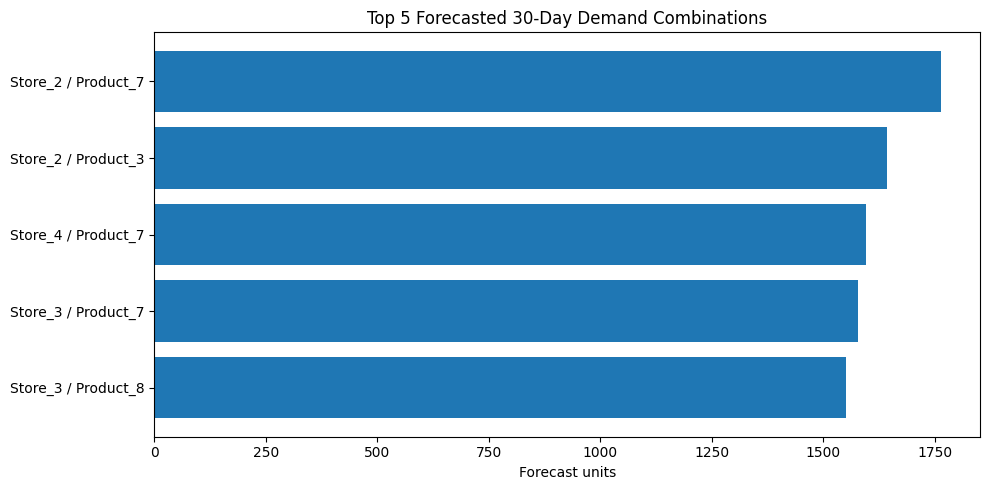

In [13]:
top_demand = inventory.sort_values("forecast_30_day_total", ascending=False).head(5)
print("Top 5 store-product combinations by forecast 30-day demand:")
display(top_demand[[
    "store", "product", "forecast_30_day_total",
    "safety_stock", "reorder_point"
]].round(0))

plt.figure(figsize=(10, 5))
plot_data = top_demand.copy()
plot_data["label"] = plot_data["store"] + " / " + plot_data["product"]
plt.barh(plot_data["label"], plot_data["forecast_30_day_total"])
plt.gca().invert_yaxis()
plt.title("Top 5 Forecasted 30-Day Demand Combinations")
plt.xlabel("Forecast units")
plt.tight_layout()
plt.show()

In [14]:
forecast_df.to_csv("retail_30_day_forecast.csv", index=False)
inventory.to_csv("retail_inventory_recommendations.csv", index=False)

print("Saved:")
print("- retail_30_day_forecast.csv")
print("- retail_inventory_recommendations.csv")

Saved:
- retail_30_day_forecast.csv
- retail_inventory_recommendations.csv
